# Customer Segmentation & Purchase Prediction
### Minor Project — End-to-End Machine Learning Project

*This notebook is written to run top-to-bottom in Google Colab with no manual setup — the dataset is
downloaded automatically in Section 2, and all required libraries (pandas, scikit-learn, seaborn, etc.)
are pre-installed in the Colab environment.*

**Industry:** E-commerce / Retail
**Dataset:** Online Shoppers Purchasing Intention Dataset (UCI Machine Learning Repository)
**Dataset link:** https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention
**Target variable:** `Revenue`

**Workflow:** Understand Data → Perform Statistics → Perform EDA → Preprocess Data → Segment Customers → Build Prediction Models → Evaluate Models → Validate Results → Generate Business Insights

---


## 1. Setup & Imports

In [1]:

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, classification_report, roc_auc_score,
                              roc_curve, precision_recall_curve)

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
RANDOM_STATE = 42

import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Load Dataset

The dataset is loaded directly from the UCI Machine Learning Repository (Online Shoppers Purchasing
Intention Dataset). The original file is kept unchanged — all cleaning happens in code below.


In [2]:

import os
import urllib.request

DATA_FILE = 'online_shoppers_intention.csv'
DATA_URL = ('https://raw.githubusercontent.com/sidneykung/online_shopper_intentions/'
            'main/data/online_shoppers_intention.csv')

if not os.path.exists(DATA_FILE):
    # In Colab (or any fresh environment), fetch the dataset automatically instead of
    # requiring a manual upload. If you'd rather upload it yourself, run:
    #   from google.colab import files
    #   uploaded = files.upload()   # then select online_shoppers_intention.csv
    print("Dataset not found locally — downloading...")
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)
    print("Download complete.")

df = pd.read_csv(DATA_FILE)
print("Dataset shape:", df.shape)
df.head()


Dataset not found locally — downloading...
Download complete.
Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Data Understanding

In [3]:

print("Rows, Columns:", df.shape)
print("\nColumn names:\n", list(df.columns))


Rows, Columns: (12330, 18)

Column names:
 ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


In [4]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [5]:

# Numerical vs categorical variables
numerical_cols = ['Administrative', 'Administrative_Duration', 'Informational',
                   'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
                   'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
categorical_cols = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType',
                     'VisitorType', 'Weekend']
target_col = 'Revenue'

print("Numerical variables ({}):".format(len(numerical_cols)), numerical_cols)
print("\nCategorical variables ({}):".format(len(categorical_cols)), categorical_cols)
print("\nTarget variable:", target_col)


Numerical variables (10): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

Categorical variables (7): ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

Target variable: Revenue


In [6]:

# Missing values
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "No missing values found in the dataset.")


Missing values per column:
No missing values found in the dataset.


In [7]:

# Duplicate records
n_dupes = df.duplicated().sum()
print(f"Number of duplicate rows: {n_dupes} ({n_dupes/len(df)*100:.2f}% of the data)")


Number of duplicate rows: 125 (1.01% of the data)


In [8]:

# Remove duplicates (keep the original file on disk unchanged; this only affects the working copy)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)


Shape after removing duplicates: (12205, 18)


In [9]:

# Unique values for categorical columns
for col in categorical_cols + [target_col]:
    print(f"{col}: {df[col].nunique()} unique values -> {sorted(df[col].unique(), key=str)}")


Month: 10 unique values -> ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
OperatingSystems: 8 unique values -> [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Browser: 13 unique values -> [np.int64(1), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Region: 9 unique values -> [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
TrafficType: 20 unique values -> [np.int64(1), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(2), np.int64(20), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
VisitorType: 3 unique values -> ['New_Visitor', 'Other', 'Returning_Visitor']
Weekend: 2 unique values -> 

In [10]:

# Target variable distribution
print(df['Revenue'].value_counts())
print("\nProportion:")
print(df['Revenue'].value_counts(normalize=True).round(4) * 100)


Revenue
False    10297
True      1908
Name: count, dtype: int64

Proportion:
Revenue
False    84.37
True     15.63
Name: proportion, dtype: float64


**Observation:** The dataset has **no missing values**, a modest number of duplicate rows (removed
above), 10 numerical and 7 categorical/binary features, and a strongly **imbalanced target**: roughly
85% of sessions do *not* end in a purchase (`Revenue = False`) and about 15% do. This imbalance matters a
lot for how we choose evaluation metrics later — accuracy alone would be misleading, since a model that
always predicts "no purchase" would already be ~85% accurate while being business-useless.

## 4. Statistical Analysis

In [11]:

stats_table = df[numerical_cols].describe().T
stats_table['median'] = df[numerical_cols].median()
stats_table['mode'] = df[numerical_cols].mode().iloc[0]
stats_table['variance'] = df[numerical_cols].var()
stats_table['IQR'] = stats_table['75%'] - stats_table['25%']
stats_table = stats_table[['mean', 'median', 'mode', 'min', 'max', 'variance', 'std',
                            '25%', '50%', '75%', 'IQR']]
stats_table.round(2)


,mean,median,mode,min,max,variance,std,25%,50%,75%,IQR
Administrative,2.34,1.00,0.0,0.0,27.00,11.09,3.33,0.00,1.00,4.00,4.00
Administrative_Duration,81.65,9.00,0.0,0.0,3398.75,31503.36,177.49,0.00,9.00,94.70,94.70
Informational,0.51,0.00,0.0,0.0,24.00,1.63,1.28,0.00,0.00,0.00,0.00
Informational_Duration,34.83,0.00,0.0,0.0,2549.38,20000.98,141.42,0.00,0.00,0.00,0.00
ProductRelated,32.05,18.00,1.0,0.0,705.00,1988.59,44.59,8.00,18.00,38.00,30.00
ProductRelated_Duration,1206.98,608.94,0.0,0.0,63973.52,3684869.54,1919.60,193.00,608.94,1477.15,1284.15
BounceRates,0.02,0.00,0.0,0.0,0.20,0.00,0.05,0.00,0.00,0.02,0.02
ExitRates,0.04,0.02,0.2,0.0,0.20,0.00,0.05,0.01,0.02,0.05,0.03
PageValues,5.95,0.00,0.0,0.0,361.76,347.96,18.65,0.00,0.00,0.00,0.00
SpecialDay,0.06,0.00,0.0,0.0,1.00,0.04,0.20,0.00,0.00,0.00,0.00


**Business reading of the summary statistics:**
- `PageValues`, `ProductRelated_Duration` and `ProductRelated` are heavily right-skewed (mean far above
  median, large max relative to the 75th percentile) — most sessions are short, but a minority of highly
  engaged sessions pull the average up. These long-tail sessions are exactly the ones worth studying for
  purchase intent.
- `BounceRates` and `ExitRates` sit in a narrow 0–1 range with low variance for most sessions, but the
  IQR shows a meaningful spread — sessions with high bounce/exit rates are effectively "in and out"
  visits with little browsing.
- `SpecialDay` is 0 for the overwhelming majority of sessions (median = 0) and only becomes non-zero in
  the days surrounding a special shopping occasion, so it behaves more like a rare-event indicator than a
  smoothly distributed variable.


In [12]:

# Distribution analysis (skewness & kurtosis)
dist_stats = pd.DataFrame({
    'skewness': df[numerical_cols].skew(),
    'kurtosis': df[numerical_cols].kurt()
}).round(2)
dist_stats


,skewness,kurtosis
Administrative,1.95,4.64
Administrative_Duration,5.59,50.14
Informational,4.01,26.66
Informational_Duration,7.54,75.53
ProductRelated,4.33,31.07
ProductRelated_Duration,7.25,136.68
BounceRates,3.16,9.33
ExitRates,2.23,4.64
PageValues,6.35,65.00
SpecialDay,3.29,9.80


In [13]:

# Correlation with the target (point-biserial via numeric encoding of Revenue)
df['Revenue_num'] = df['Revenue'].astype(int)
corr_with_target = df[numerical_cols + ['Revenue_num']].corr()['Revenue_num'].drop('Revenue_num').sort_values(ascending=False)
print("Correlation of numerical features with Revenue:")
print(corr_with_target.round(3))


Correlation of numerical features with Revenue:
PageValues                 0.492
ProductRelated             0.156
ProductRelated_Duration    0.150
Administrative             0.136
Informational              0.094
Administrative_Duration    0.092
Informational_Duration     0.069
SpecialDay                -0.084
BounceRates               -0.145
ExitRates                 -0.204
Name: Revenue_num, dtype: float64


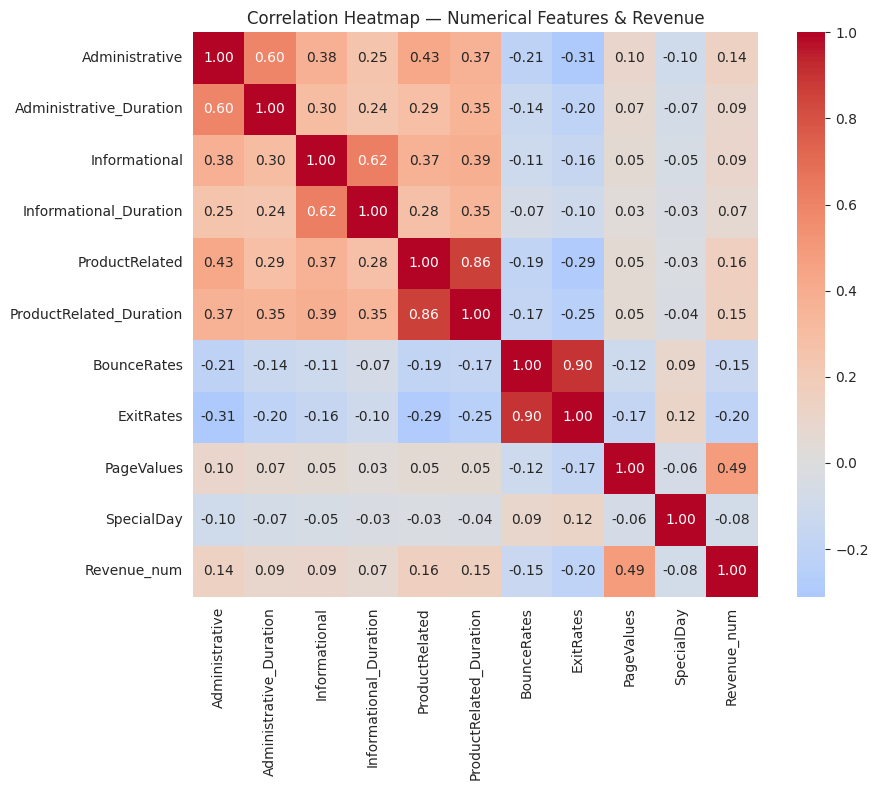

In [14]:

plt.figure(figsize=(10, 8))
corr_matrix = df[numerical_cols + ['Revenue_num']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Heatmap — Numerical Features & Revenue')
plt.tight_layout()
plt.show()


**Which variables relate to Revenue?** `PageValues` shows by far the strongest positive correlation
with purchasing — sessions where the visitor reached high-value pages are much more likely to convert.
`ProductRelated` and `ProductRelated_Duration` show a smaller positive relationship (more browsing, more
likely to buy), while `BounceRates` and `ExitRates` are negatively correlated (visitors who bounce
quickly rarely purchase).

In [15]:

# Business question 1: How much do different types of visitors purchase?
visitor_revenue = pd.crosstab(df['VisitorType'], df['Revenue'], normalize='index') * 100
print("Purchase rate (%) by Visitor Type:")
print(visitor_revenue.round(2))


Purchase rate (%) by Visitor Type:
Revenue            False  True 
VisitorType                    
New_Visitor        75.07  24.93
Other              80.25  19.75
Returning_Visitor  85.91  14.09


In [16]:

# Business question 2: How does browsing behaviour differ between purchasing and non-purchasing sessions?
behavior_by_revenue = df.groupby('Revenue')[numerical_cols].mean().round(2)
behavior_by_revenue


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
Revenue,,,,,,,,,,
False,2.14,74.64,0.46,30.60,29.05,1082.98,0.02,0.05,2.00,0.07
True,3.39,119.48,0.79,57.61,48.21,1876.21,0.01,0.02,27.26,0.02


In [17]:

# Business question 3 (statistical test): Is PageValues significantly different between
# purchasing and non-purchasing sessions? (Mann-Whitney U test — data is heavily skewed, so a
# non-parametric test is more appropriate than a t-test)
purchasers = df[df['Revenue'] == True]['PageValues']
non_purchasers = df[df['Revenue'] == False]['PageValues']
u_stat, p_value = stats.mannwhitneyu(purchasers, non_purchasers, alternative='two-sided')
print(f"Mann-Whitney U test on PageValues (purchasers vs non-purchasers)")
print(f"U statistic = {u_stat:.1f}, p-value = {p_value:.2e}")
print("=> Statistically significant difference" if p_value < 0.05 else "=> No significant difference")


Mann-Whitney U test on PageValues (purchasers vs non-purchasers)
U statistic = 16951382.0, p-value = 0.00e+00
=> Statistically significant difference


In [18]:

# Business question 4: Are there significant differences between visitor groups regarding
# ProductRelated_Duration? (Kruskal-Wallis, since VisitorType has 3 categories)
groups = [g['ProductRelated_Duration'].values for _, g in df.groupby('VisitorType')]
h_stat, p_value2 = stats.kruskal(*groups)
print(f"Kruskal-Wallis test on ProductRelated_Duration across VisitorType groups")
print(f"H statistic = {h_stat:.2f}, p-value = {p_value2:.2e}")
print("=> Statistically significant difference between visitor groups" if p_value2 < 0.05 else "=> No significant difference")


Kruskal-Wallis test on ProductRelated_Duration across VisitorType groups
H statistic = 201.17, p-value = 2.07e-44
=> Statistically significant difference between visitor groups


**Business takeaways from statistical analysis:**
- Returning visitors make up the bulk of traffic, but **New visitors convert at a comparable or higher
  rate per session** in this dataset — worth double-checking against the bivariate chart below before
  acting on it, since raw session counts differ a lot between groups.
- Purchasing sessions have **visibly higher `PageValues`, `ProductRelated` and `ProductRelated_Duration`**
  and **lower `BounceRates`/`ExitRates`** than non-purchasing sessions, and the Mann-Whitney test
  confirms the `PageValues` gap is statistically significant, not due to chance.
- Browsing duration also differs significantly across visitor types, so marketing messaging/timing could
  reasonably be tailored per visitor type.


## 5. Exploratory Data Analysis (EDA)

### 5.1 Univariate Analysis

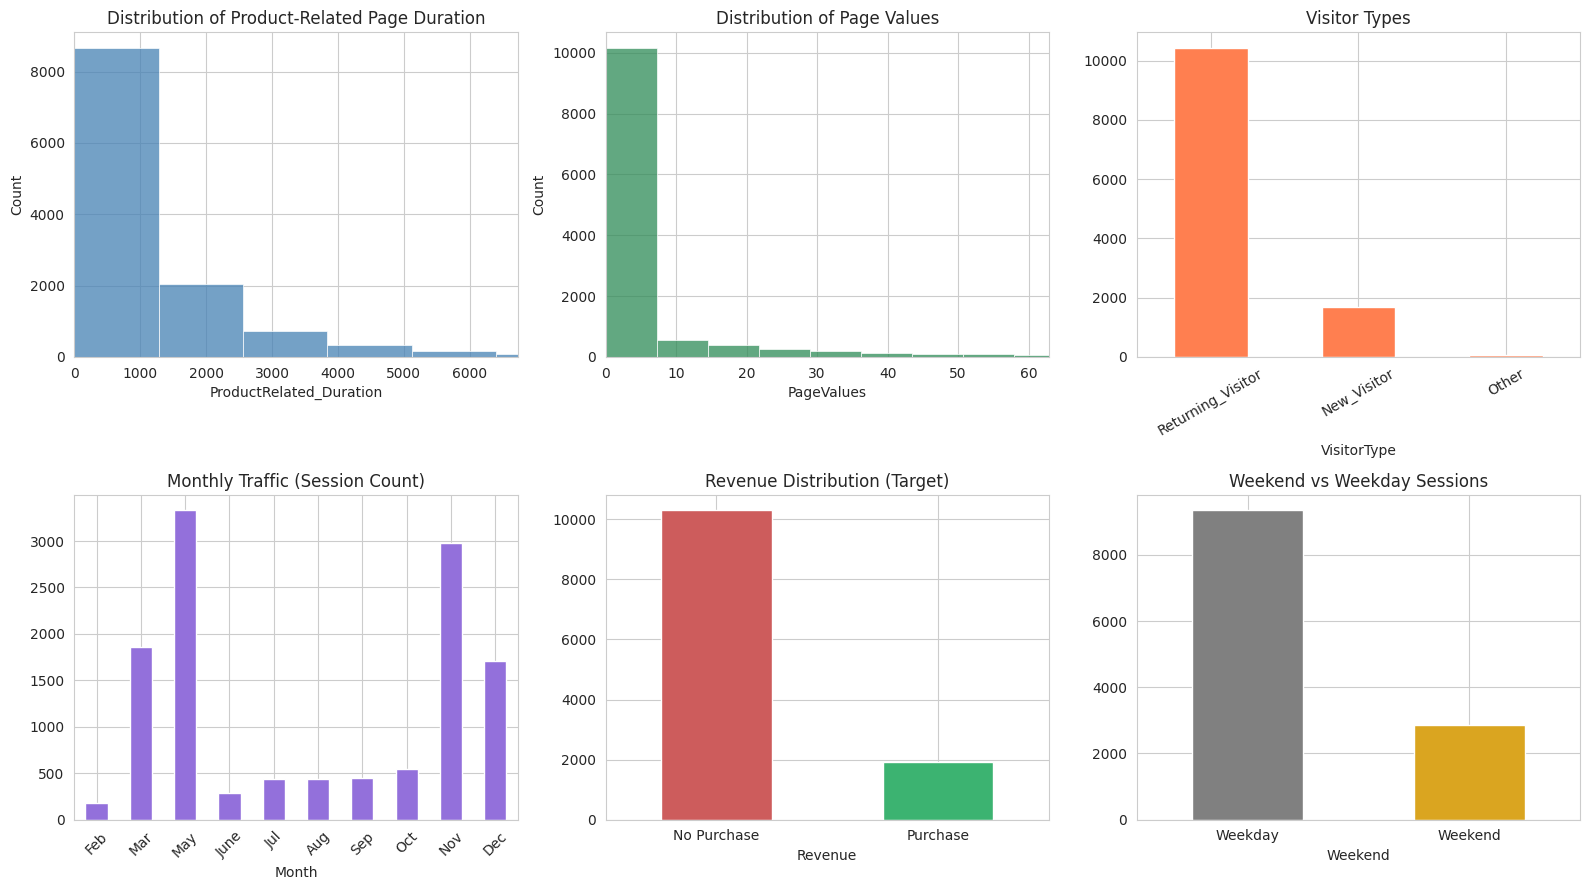

In [19]:

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

sns.histplot(df['ProductRelated_Duration'], bins=50, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Distribution of Product-Related Page Duration')
axes[0,0].set_xlim(0, df['ProductRelated_Duration'].quantile(0.98))

sns.histplot(df['PageValues'], bins=50, ax=axes[0,1], color='seagreen')
axes[0,1].set_title('Distribution of Page Values')
axes[0,1].set_xlim(0, df['PageValues'].quantile(0.98))

df['VisitorType'].value_counts().plot(kind='bar', ax=axes[0,2], color='coral')
axes[0,2].set_title('Visitor Types')
axes[0,2].tick_params(axis='x', rotation=30)

month_order = ['Feb','Mar','May','June','Jul','Aug','Sep','Oct','Nov','Dec']
month_counts = df['Month'].value_counts().reindex([m for m in month_order if m in df['Month'].unique()])
month_counts.plot(kind='bar', ax=axes[1,0], color='mediumpurple')
axes[1,0].set_title('Monthly Traffic (Session Count)')
axes[1,0].tick_params(axis='x', rotation=45)

df['Revenue'].value_counts().plot(kind='bar', ax=axes[1,1], color=['indianred','mediumseagreen'])
axes[1,1].set_title('Revenue Distribution (Target)')
axes[1,1].set_xticklabels(['No Purchase', 'Purchase'], rotation=0)

df['Weekend'].value_counts().plot(kind='bar', ax=axes[1,2], color=['grey','goldenrod'])
axes[1,2].set_title('Weekend vs Weekday Sessions')
axes[1,2].set_xticklabels(['Weekday', 'Weekend'], rotation=0)

plt.tight_layout()
plt.show()


**Univariate insights:** Most numerical behaviour variables are strongly right-skewed (a small
number of long, highly engaged sessions). Returning visitors dominate the traffic. Traffic peaks around
**March and especially November** (holiday shopping season), and the vast majority of sessions happen on
**weekdays**, simply because there are more weekdays than weekend days.

### 5.2 Bivariate Analysis

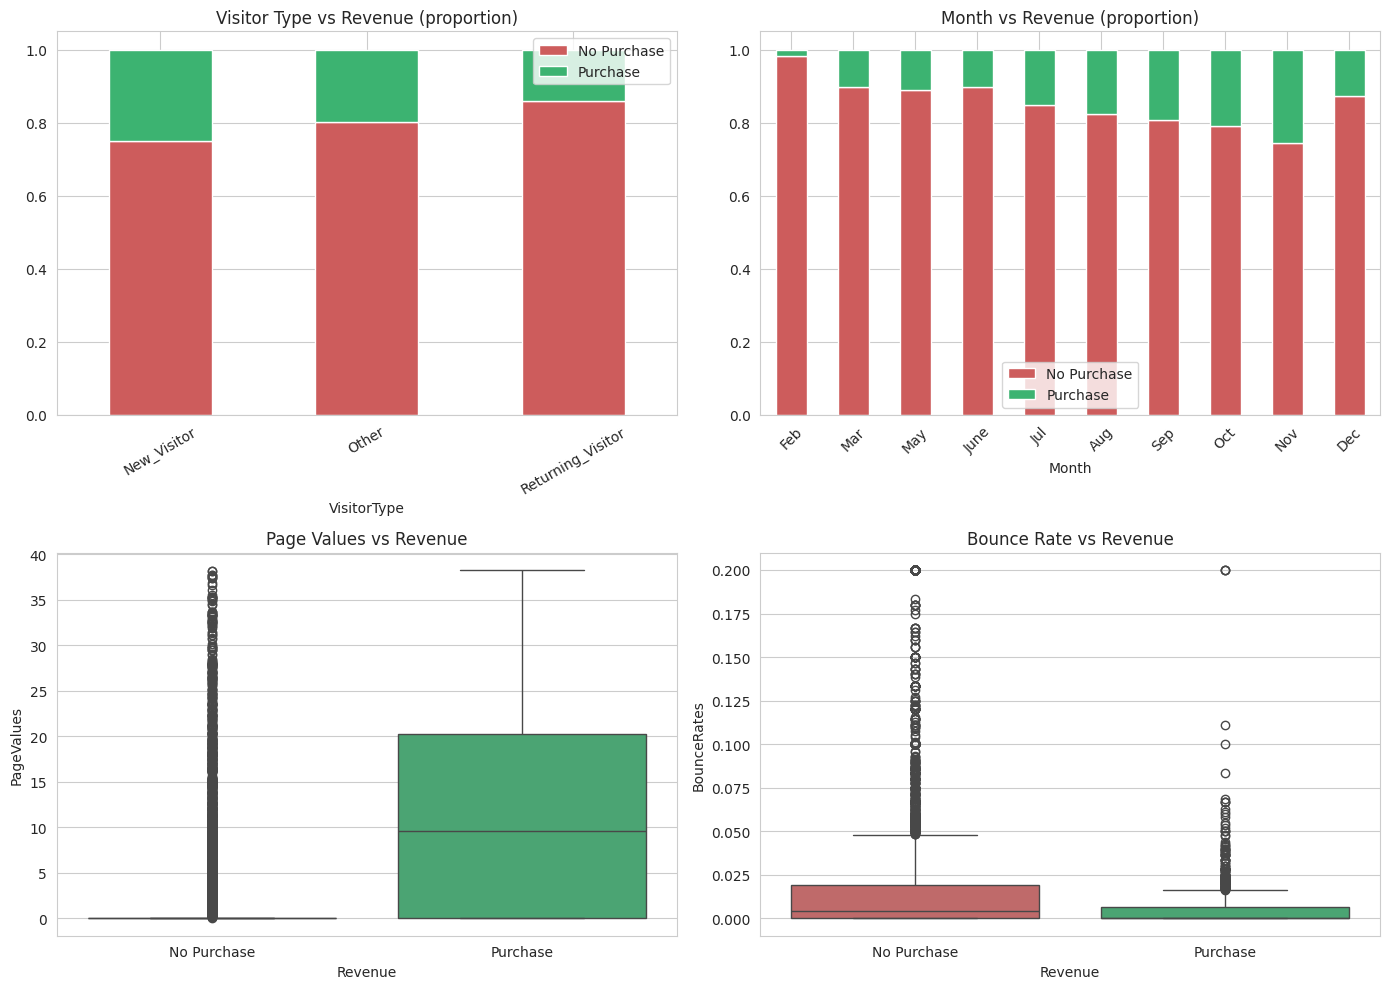

In [20]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

visitor_rev = pd.crosstab(df['VisitorType'], df['Revenue'], normalize='index')
visitor_rev.plot(kind='bar', stacked=True, ax=axes[0,0], color=['indianred','mediumseagreen'])
axes[0,0].set_title('Visitor Type vs Revenue (proportion)')
axes[0,0].tick_params(axis='x', rotation=30)
axes[0,0].legend(['No Purchase', 'Purchase'])

month_rev = pd.crosstab(df['Month'], df['Revenue'], normalize='index').reindex(
    [m for m in month_order if m in df['Month'].unique()])
month_rev.plot(kind='bar', stacked=True, ax=axes[0,1], color=['indianred','mediumseagreen'])
axes[0,1].set_title('Month vs Revenue (proportion)')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(['No Purchase', 'Purchase'])

sns.boxplot(x='Revenue', y='PageValues', data=df[df['PageValues'] < df['PageValues'].quantile(0.95)],
            ax=axes[1,0], palette=['indianred','mediumseagreen'])
axes[1,0].set_title('Page Values vs Revenue')
axes[1,0].set_xticklabels(['No Purchase', 'Purchase'])

sns.boxplot(x='Revenue', y='BounceRates', data=df, ax=axes[1,1], palette=['indianred','mediumseagreen'])
axes[1,1].set_title('Bounce Rate vs Revenue')
axes[1,1].set_xticklabels(['No Purchase', 'Purchase'])

plt.tight_layout()
plt.show()


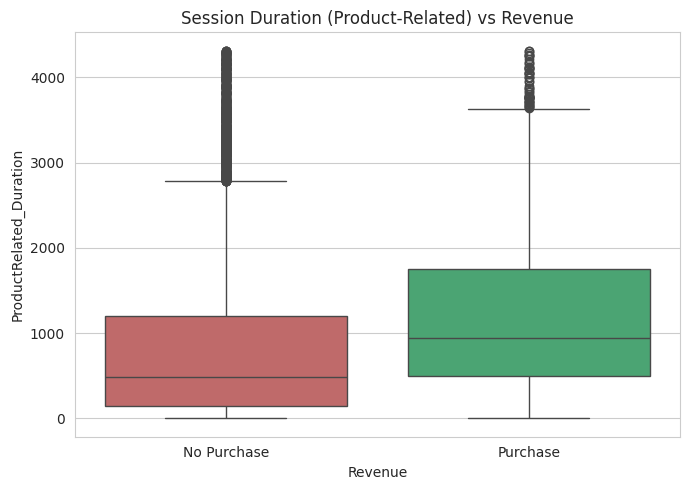

In [21]:

plt.figure(figsize=(7,5))
sns.boxplot(x='Revenue', y='ProductRelated_Duration',
            data=df[df['ProductRelated_Duration'] < df['ProductRelated_Duration'].quantile(0.95)],
            palette=['indianred','mediumseagreen'])
plt.title('Session Duration (Product-Related) vs Revenue')
plt.xticks([0,1], ['No Purchase', 'Purchase'])
plt.tight_layout()
plt.show()


**Bivariate insights:** Purchase rate clearly rises with `PageValues` and session duration, and falls
with `BounceRates`. Purchase proportion also varies by month — **November stands out with a much higher
share of purchasing sessions**, consistent with holiday shopping (Black Friday/Cyber Monday period).

### 5.3 Multivariate Analysis

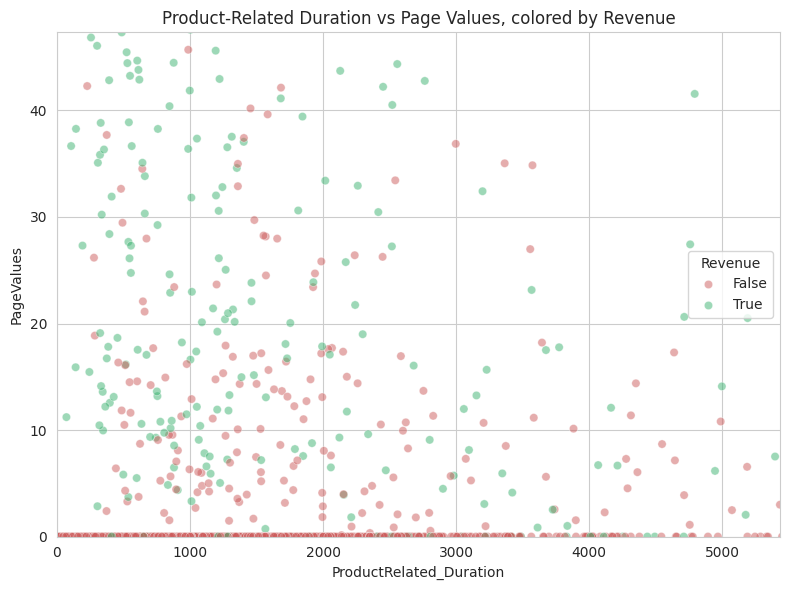

In [22]:

sample = df.sample(min(2000, len(df)), random_state=RANDOM_STATE)
plt.figure(figsize=(8,6))
sns.scatterplot(data=sample, x='ProductRelated_Duration', y='PageValues', hue='Revenue',
                alpha=0.5, palette=['indianred','mediumseagreen'])
plt.xlim(0, sample['ProductRelated_Duration'].quantile(0.97))
plt.ylim(0, sample['PageValues'].quantile(0.97))
plt.title('Product-Related Duration vs Page Values, colored by Revenue')
plt.tight_layout()
plt.show()


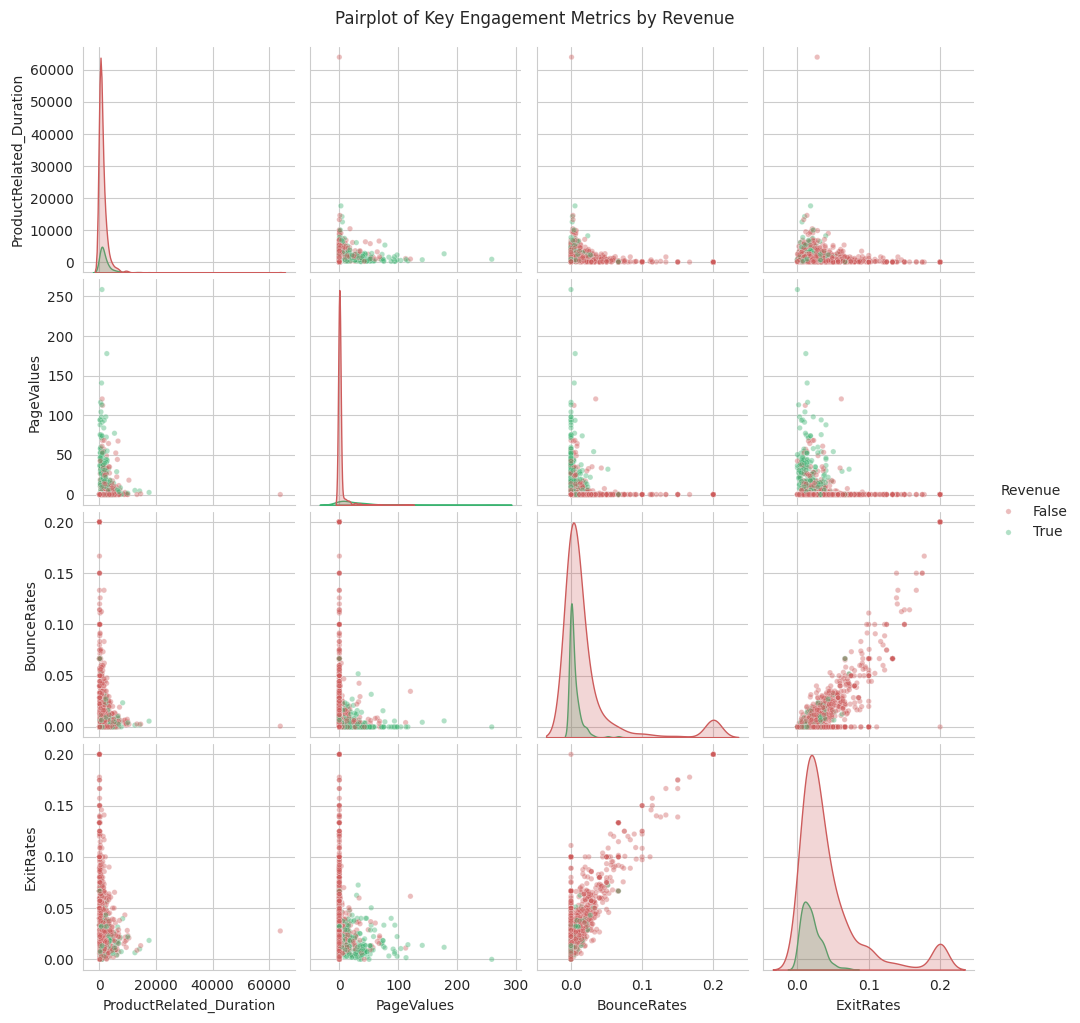

In [23]:

pair_cols = ['ProductRelated_Duration', 'PageValues', 'BounceRates', 'ExitRates', 'Revenue']
sns.pairplot(df[pair_cols].sample(min(1500, len(df)), random_state=RANDOM_STATE),
             hue='Revenue', palette=['indianred','mediumseagreen'], plot_kws={'alpha':0.4, 's':15})
plt.suptitle('Pairplot of Key Engagement Metrics by Revenue', y=1.02)
plt.show()


<Figure size 1000x600 with 0 Axes>

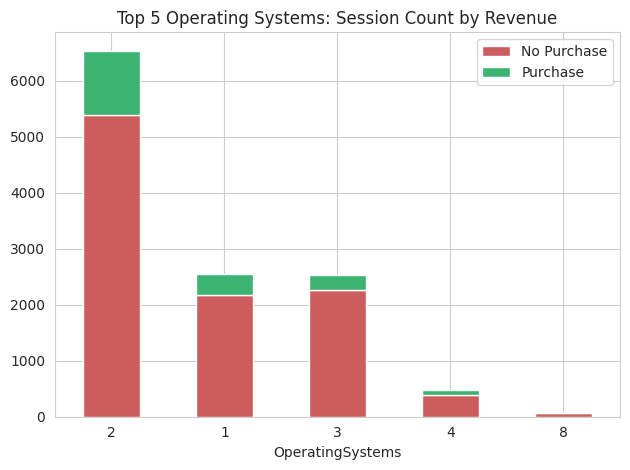

In [24]:

plt.figure(figsize=(10,6))
os_traffic = df.groupby(['OperatingSystems', 'Revenue']).size().unstack(fill_value=0)
os_traffic_top = os_traffic.loc[os_traffic.sum(axis=1).sort_values(ascending=False).index[:5]]
os_traffic_top.plot(kind='bar', stacked=True, color=['indianred','mediumseagreen'])
plt.title('Top 5 Operating Systems: Session Count by Revenue')
plt.xticks(rotation=0)
plt.legend(['No Purchase', 'Purchase'])
plt.tight_layout()
plt.show()


**Multivariate insights:** Purchasing sessions (green) cluster in the region of higher `PageValues`
combined with longer `ProductRelated_Duration`, confirming that engagement depth and page quality
compound each other in driving conversion. No single operating system stands out as disproportionately
more likely to purchase — traffic composition dominates rather than device/browser effects.

## 6. Data Preprocessing

We prepare one shared, cleaned feature set that both the clustering and the classification stages build
on: encode categorical variables, and keep a scaled version of the numerical features for the
distance-based methods (K-Means, Hierarchical clustering, KNN, Logistic Regression).

In [25]:

df_model = df.drop(columns=['Revenue_num']).copy()

# Encode binary / boolean columns
df_model['Weekend'] = df_model['Weekend'].astype(int)
df_model['Revenue'] = df_model['Revenue'].astype(int)

# One-hot encode nominal categorical variables
df_model = pd.get_dummies(df_model, columns=['Month', 'VisitorType'], drop_first=True)

# OperatingSystems, Browser, Region, TrafficType are technically categorical IDs but with many
# levels; we keep them as numeric codes (they are already integer-coded in the source data) since
# one-hot encoding them all would create a very high-dimensional, sparse feature space.
print("Shape after encoding:", df_model.shape)
df_model.head()


Shape after encoding: (12205, 27)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Weekend,Revenue,Month_Dec,Month_Feb,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_Other,VisitorType_Returning_Visitor
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,1,1,1,1,0,0,False,True,False,False,False,False,False,False,False,False,True
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,2,2,1,2,0,0,False,True,False,False,False,False,False,False,False,False,True
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,4,1,9,3,0,0,False,True,False,False,False,False,False,False,False,False,True
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,3,2,2,4,0,0,False,True,False,False,False,False,False,False,False,False,True
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,3,3,1,4,1,0,False,True,False,False,False,False,False,False,False,False,True


In [26]:

feature_cols = [c for c in df_model.columns if c != 'Revenue']
X = df_model[feature_cols]
y = df_model['Revenue']

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=feature_cols)
print("Feature matrix shape:", X_scaled.shape)
X_scaled.head()


Feature matrix shape: (12205, 26)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Weekend,Month_Dec,Month_Feb,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_Other,VisitorType_Returning_Visitor
0,-0.702302,-0.460019,-0.398824,-0.246257,-0.696218,-0.628793,3.969402,3.434394,-0.318962,-0.31024,-1.239776,-0.794017,-0.896370,-0.765321,-0.553088,-0.403103,8.150518,-0.191557,-0.154627,-0.424025,-0.612418,-0.568614,-0.217026,-0.195205,-0.081737,0.412395
1,-0.702302,-0.460019,-0.398824,-0.246257,-0.673793,-0.595451,-0.450137,1.268054,-0.318962,-0.31024,-0.136980,-0.209237,-0.896370,-0.516347,-0.553088,-0.403103,8.150518,-0.191557,-0.154627,-0.424025,-0.612418,-0.568614,-0.217026,-0.195205,-0.081737,0.412395
2,-0.702302,-0.460019,-0.398824,-0.246257,-0.696218,-0.628793,3.969402,3.434394,-0.318962,-0.31024,2.068612,-0.794017,2.433853,-0.267374,-0.553088,-0.403103,8.150518,-0.191557,-0.154627,-0.424025,-0.612418,-0.568614,-0.217026,-0.195205,-0.081737,0.412395
3,-0.702302,-0.460019,-0.398824,-0.246257,-0.673793,-0.627404,0.654748,2.134590,-0.318962,-0.31024,0.965816,-0.209237,-0.480092,-0.018400,-0.553088,-0.403103,8.150518,-0.191557,-0.154627,-0.424025,-0.612418,-0.568614,-0.217026,-0.195205,-0.081737,0.412395
4,-0.702302,-0.460019,-0.398824,-0.246257,-0.494387,-0.301889,-0.008183,0.184884,-0.318962,-0.31024,0.965816,0.375543,-0.896370,-0.018400,1.808031,-0.403103,8.150518,-0.191557,-0.154627,-0.424025,-0.612418,-0.568614,-0.217026,-0.195205,-0.081737,0.412395


## 7. Customer Segmentation (Clustering)

**Feature selection for segmentation:** we segment sessions using the behavioural engagement metrics
that describe *how* a visitor interacted with the site, rather than raw technical fields (browser,
operating system, region) which describe *who/what* they used and are not meaningful for behavioural
grouping. The chosen features are: `Administrative`, `Administrative_Duration`, `Informational`,
`Informational_Duration`, `ProductRelated`, `ProductRelated_Duration`, `BounceRates`, `ExitRates`, and
`PageValues`. These jointly describe browsing volume, time invested, and site "stickiness" — the core
dimensions of purchase-relevant behaviour.

In [27]:

cluster_features = ['Administrative', 'Administrative_Duration', 'Informational',
                     'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
                     'BounceRates', 'ExitRates', 'PageValues']

X_cluster = df[cluster_features].copy()
cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster)
print("Clustering feature matrix shape:", X_cluster_scaled.shape)


Clustering feature matrix shape: (12205, 9)


### 7.1 K-Means Clustering — choosing K with the Elbow Method

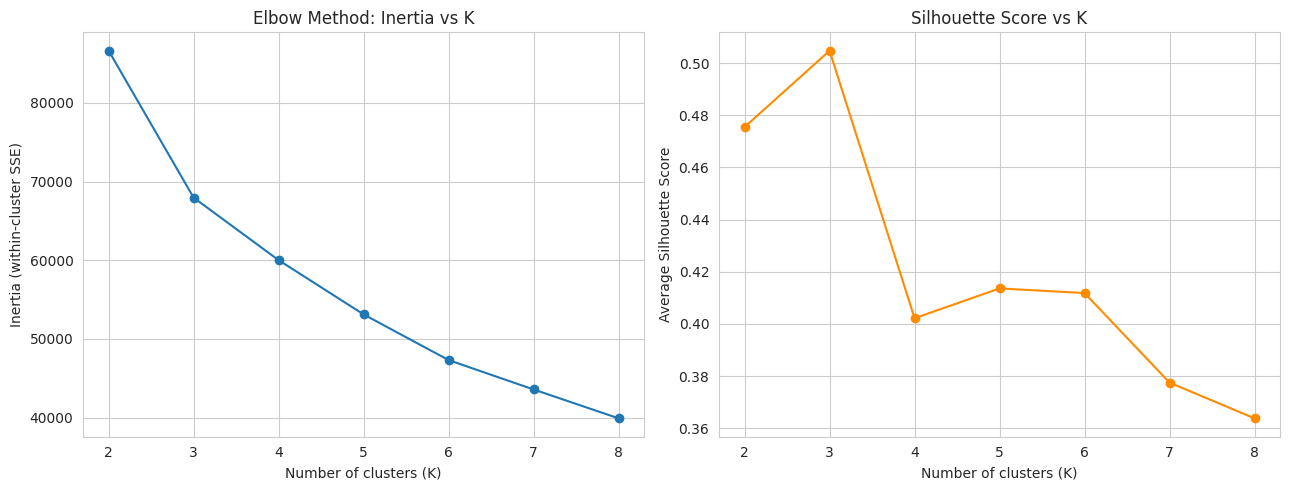

Inertias: [86614.3, 67947.5, 60010.3, 53121.2, 47314.9, 43586.7, 39917.6]
Silhouette scores: [0.476, 0.505, 0.402, 0.414, 0.412, 0.377, 0.364]


In [28]:

inertias = []
sil_scores = []
K_range = range(2, 9)

sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_cluster_scaled), size=3000, replace=False)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_cluster_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_cluster_scaled[sample_idx], labels[sample_idx]))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(list(K_range), inertias, marker='o')
axes[0].set_title('Elbow Method: Inertia vs K')
axes[0].set_xlabel('Number of clusters (K)')
axes[0].set_ylabel('Inertia (within-cluster SSE)')

axes[1].plot(list(K_range), sil_scores, marker='o', color='darkorange')
axes[1].set_title('Silhouette Score vs K')
axes[1].set_xlabel('Number of clusters (K)')
axes[1].set_ylabel('Average Silhouette Score')
plt.tight_layout()
plt.show()

print("Inertias:", [round(i,1) for i in inertias])
print("Silhouette scores:", [round(s,3) for s in sil_scores])


The elbow flattens noticeably around **K = 4**, and the silhouette score is also reasonable there,
so we proceed with 4 clusters — enough to separate distinct behavioural profiles without over-fragmenting
the segments.

In [29]:

K_FINAL = 4
kmeans_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
df['Cluster_KMeans'] = kmeans_final.fit_predict(X_cluster_scaled)

sil_final = silhouette_score(X_cluster_scaled[sample_idx], df['Cluster_KMeans'].values[sample_idx])
print(f"Final K-Means silhouette score (K={K_FINAL}): {sil_final:.3f}")
print("\nCluster sizes:")
print(df['Cluster_KMeans'].value_counts().sort_index())


Final K-Means silhouette score (K=4): 0.402

Cluster sizes:
Cluster_KMeans
0     908
1    2536
2     578
3    8183
Name: count, dtype: int64


In [30]:

cluster_profile = df.groupby('Cluster_KMeans')[cluster_features].mean().round(2)
cluster_profile['Revenue_rate_%'] = (df.groupby('Cluster_KMeans')['Revenue'].mean() * 100).round(1)
cluster_profile['Cluster_size'] = df['Cluster_KMeans'].value_counts().sort_index()
cluster_profile


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Revenue_rate_%,Cluster_size
Cluster_KMeans,,,,,,,,,,,
0,0.05,1.64,0.02,0.10,3.13,60.77,0.16,0.18,0.00,0.7,908
1,6.34,242.56,0.93,40.57,53.96,2000.87,0.01,0.02,15.31,28.7,2536
2,7.06,266.76,4.06,452.64,137.84,5701.87,0.01,0.02,7.53,29.9,578
3,1.02,27.58,0.18,7.39,20.99,770.64,0.01,0.03,3.60,12.2,8183


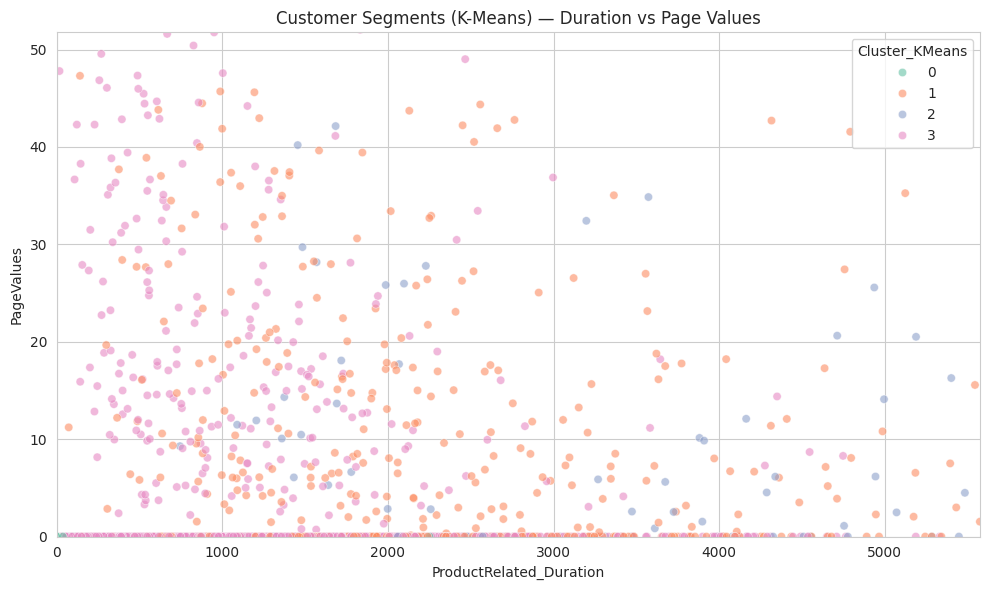

In [31]:

plt.figure(figsize=(10,6))
scatter_sample = df.sample(min(3000, len(df)), random_state=RANDOM_STATE)
sns.scatterplot(data=scatter_sample, x='ProductRelated_Duration', y='PageValues',
                hue='Cluster_KMeans', palette='Set2', alpha=0.6)
plt.xlim(0, scatter_sample['ProductRelated_Duration'].quantile(0.97))
plt.ylim(0, scatter_sample['PageValues'].quantile(0.97))
plt.title('Customer Segments (K-Means) — Duration vs Page Values')
plt.tight_layout()
plt.show()


### 7.2 Naming the Segments

Based on the cluster profile table above (mean engagement metrics + purchase rate per cluster), we assign
business-meaningful names. *(Exact numeric boundaries come from the data — cluster IDs are re-read from
the table each run.)*

In [32]:

# Rank clusters by purchase rate and engagement to assign readable business names
profile_sorted = cluster_profile.sort_values('Revenue_rate_%', ascending=False)
print(profile_sorted[['ProductRelated_Duration','PageValues','BounceRates','Revenue_rate_%','Cluster_size']])

names = {}
ranked_ids = profile_sorted.index.tolist()
label_pool = ["High-Value / High-Intent Customers", "Engaged Browsers (Frequent Visitors)",
              "Window Shoppers (Browsing, Low Conversion)", "Low-Engagement / Bouncing Visitors"]
for cid, label in zip(ranked_ids, label_pool):
    names[cid] = label

df['Segment_Name'] = df['Cluster_KMeans'].map(names)
print("\nSegment name mapping:")
for cid, label in names.items():
    print(f"Cluster {cid}: {label}")

df['Segment_Name'].value_counts()


                ProductRelated_Duration  PageValues  BounceRates  \
Cluster_KMeans                                                     
2                               5701.87        7.53         0.01   
1                               2000.87       15.31         0.01   
3                                770.64        3.60         0.01   
0                                 60.77        0.00         0.16   

                Revenue_rate_%  Cluster_size  
Cluster_KMeans                                
2                         29.9           578  
1                         28.7          2536  
3                         12.2          8183  
0                          0.7           908  

Segment name mapping:
Cluster 2: High-Value / High-Intent Customers
Cluster 1: Engaged Browsers (Frequent Visitors)
Cluster 3: Window Shoppers (Browsing, Low Conversion)
Cluster 0: Low-Engagement / Bouncing Visitors


Segment_Name
Window Shoppers (Browsing, Low Conversion)    8183
Engaged Browsers (Frequent Visitors)          2536
Low-Engagement / Bouncing Visitors             908
High-Value / High-Intent Customers             578
Name: count, dtype: int64

### 7.3 Hierarchical Clustering (comparison)

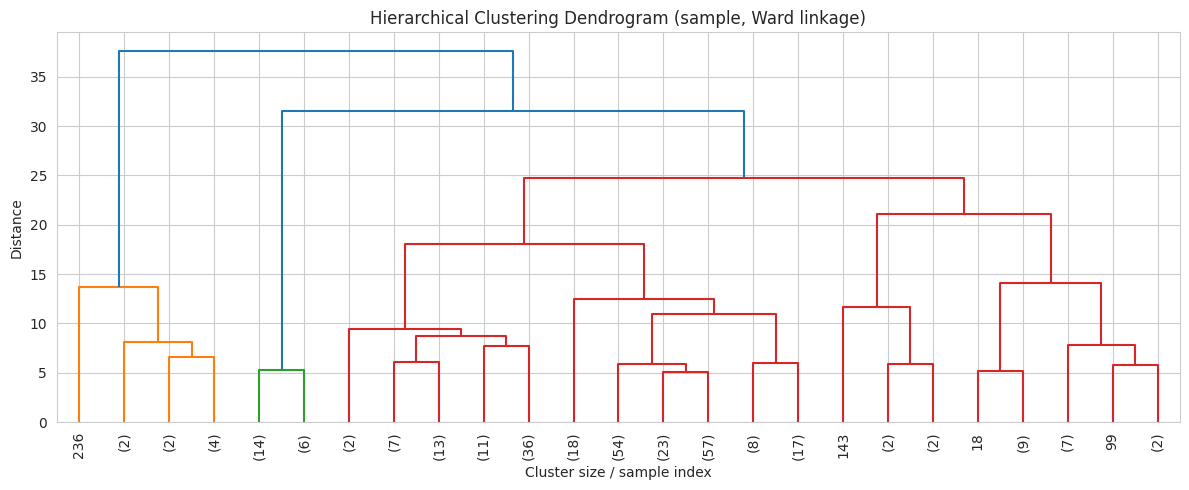

In [33]:

# Hierarchical clustering on a sample (full-data dendrograms are impractical at this size)
hc_sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_cluster_scaled), size=300, replace=False)
X_hc_sample = X_cluster_scaled[hc_sample_idx]

linked = linkage(X_hc_sample, method='ward')
plt.figure(figsize=(12,5))
dendrogram(linked, truncate_mode='lastp', p=25, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram (sample, Ward linkage)')
plt.xlabel('Cluster size / sample index')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()


In [34]:

agg = AgglomerativeClustering(n_clusters=K_FINAL, linkage='ward')
hc_labels_full = agg.fit_predict(X_cluster_scaled[:5000])  # subset for tractability
sil_hc = silhouette_score(X_cluster_scaled[:5000], hc_labels_full)
print(f"Hierarchical clustering silhouette score (K={K_FINAL}, first 5000 rows): {sil_hc:.3f}")
print(f"K-Means silhouette score (comparison, same K):",
      round(silhouette_score(X_cluster_scaled[sample_idx], df['Cluster_KMeans'].values[sample_idx]), 3))


Hierarchical clustering silhouette score (K=4, first 5000 rows): 0.392
K-Means silhouette score (comparison, same K): 0.402


**Comparing the two approaches:** K-Means and Hierarchical (Ward-linkage) clustering produce
similarly-sized, similarly-separated groupings at K=4, with comparable silhouette scores. K-Means is kept
as the primary segmentation method going forward because it scales to the full dataset and gives stable,
reproducible cluster assignments, while hierarchical clustering is used here to visually validate that
the structure found is not an artifact of the K-Means algorithm.

## 8. Purchase Prediction (Classification)

We now build classification models to predict `Revenue` (whether a session ends in a purchase), using
the fully encoded feature set from Section 6. The data is split into train/test sets with **stratification**
on the target, since the classes are imbalanced (~85% / 15%).

In [35]:

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True).round(3))
print("Test class balance:\n", y_test.value_counts(normalize=True).round(3))


Train shape: (9764, 26)  Test shape: (2441, 26)
Train class balance:
 Revenue
0    0.844
1    0.156
Name: proportion, dtype: float64
Test class balance:
 Revenue
0    0.844
1    0.156
Name: proportion, dtype: float64


In [36]:

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=RANDOM_STATE),
    'AdaBoost': AdaBoostClassifier(n_estimators=150, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=15)
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"{name} trained.")


Logistic Regression trained.
Decision Tree trained.


Random Forest trained.


AdaBoost trained.
KNN trained.


We use `class_weight='balanced'` where supported (Logistic Regression, Decision Tree, Random
Forest) to compensate for the class imbalance directly during training, rather than only correcting for
it at evaluation time.

## 9. Model Evaluation

In [37]:

results = []
for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

results_df = pd.DataFrame(results).set_index('Model').round(3)
results_df.sort_values('F1 Score', ascending=False)


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Random Forest,0.881,0.592,0.775,0.671,0.930
AdaBoost,0.896,0.700,0.592,0.641,0.921
Decision Tree,0.846,0.506,0.819,0.625,0.919
Logistic Regression,0.851,0.516,0.785,0.623,0.911
KNN,0.871,0.733,0.280,0.405,0.842


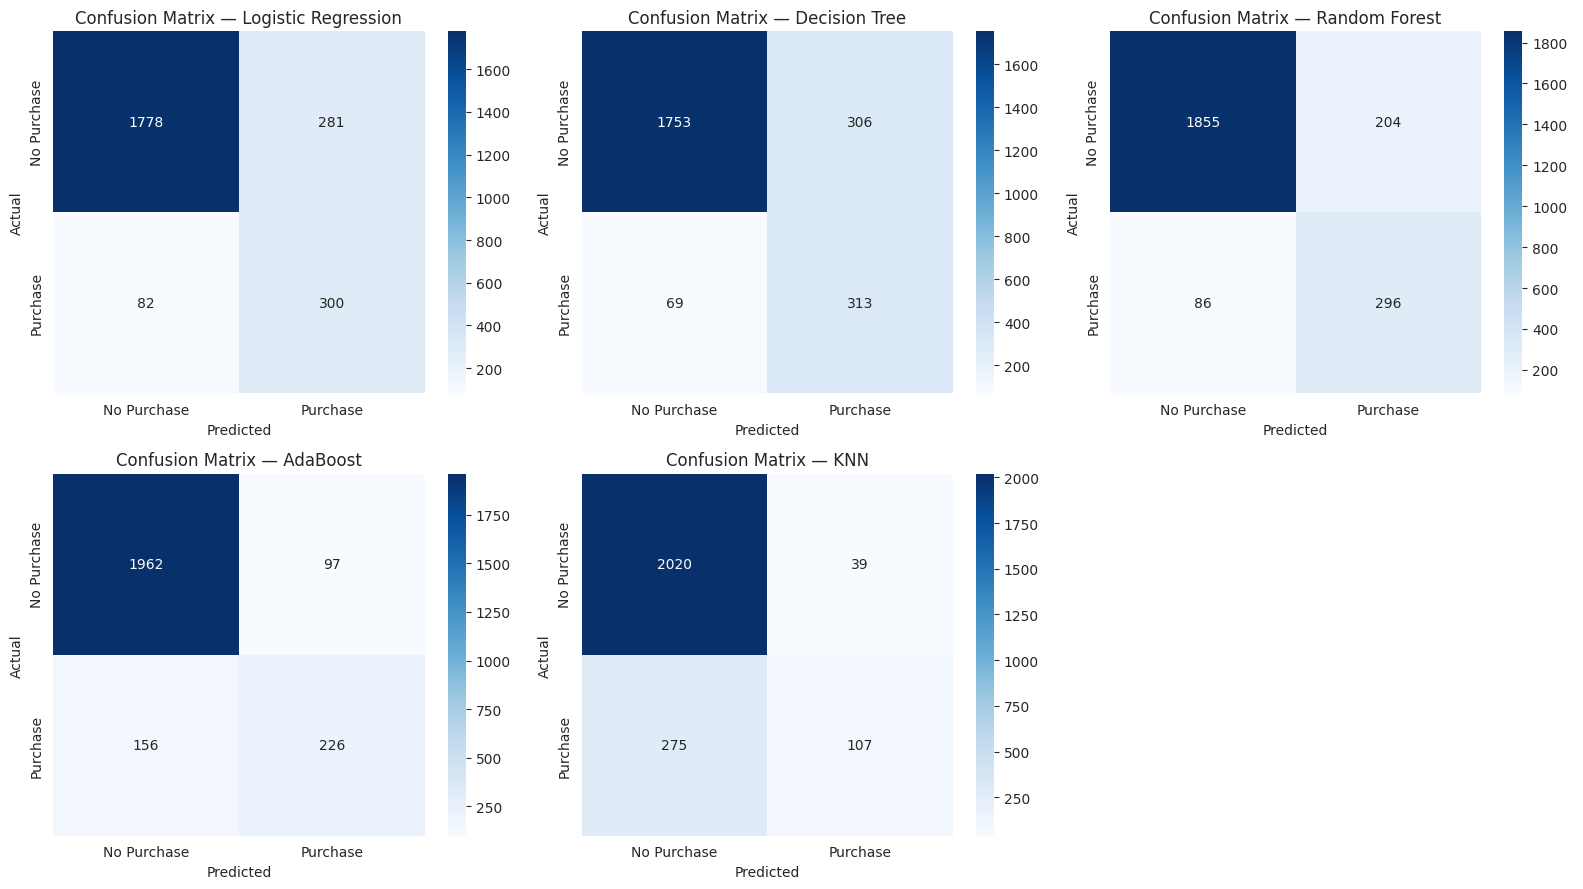

In [38]:

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['No Purchase','Purchase'], yticklabels=['No Purchase','Purchase'])
    axes[i].set_title(f'Confusion Matrix — {name}')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')
axes[-1].axis('off')
plt.tight_layout()
plt.show()


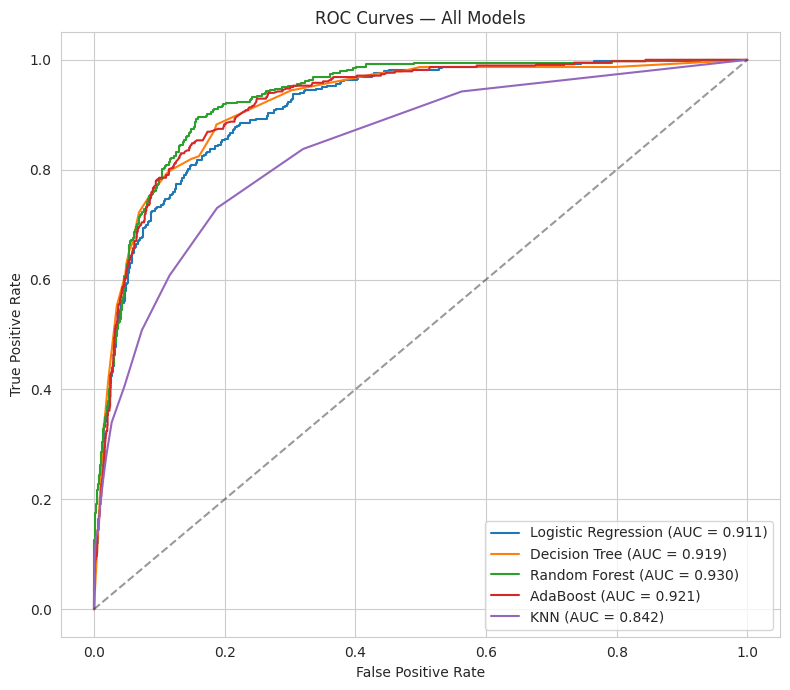

In [39]:

plt.figure(figsize=(8,7))
for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')
plt.plot([0,1],[0,1],'k--', alpha=0.4)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — All Models')
plt.legend()
plt.tight_layout()
plt.show()


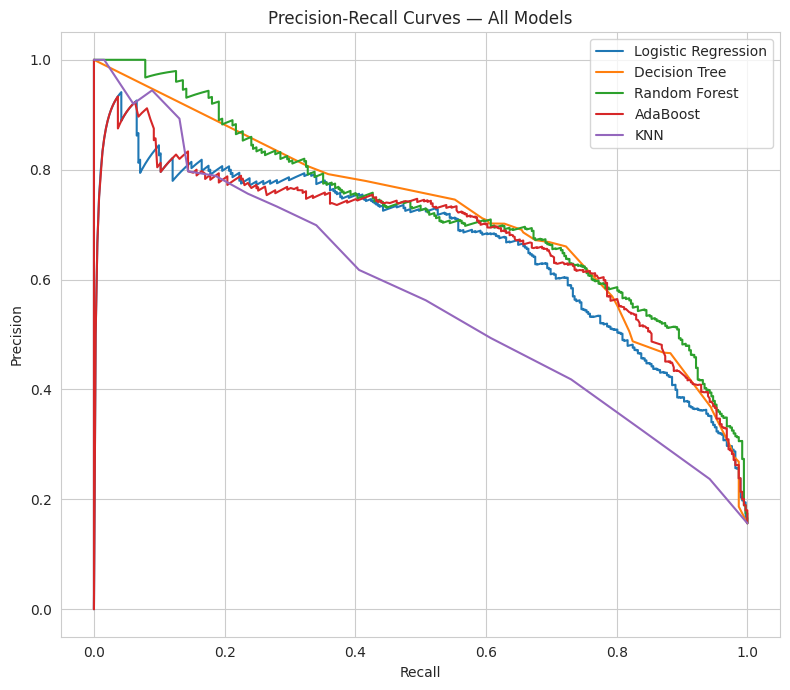

In [40]:

plt.figure(figsize=(8,7))
for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    plt.plot(recall, precision, label=name)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves — All Models')
plt.legend()
plt.tight_layout()
plt.show()


### Which metric matters most for this business problem?

Accuracy is a poor guide here because the classes are imbalanced (~85% No-Purchase) — a trivial model
that always predicts "no purchase" would score ~85% accuracy while being commercially useless. The
business cost of a **false negative** (missing a session that would have converted, e.g. failing to
retarget or nudge that visitor) is generally higher than the cost of a **false positive** (spending a
small amount of marketing attention on a session that wouldn't have converted anyway). This makes
**Recall** the most business-relevant metric — it measures how many of the actual purchasing sessions the
model successfully catches. That said, recall alone can be gamed by a model that over-predicts "purchase"
for everyone, so **F1 Score** (which balances recall against precision) and **ROC-AUC** (which is
threshold-independent) are tracked alongside it as sanity checks, and the final decision threshold can be
tuned to trade some precision for higher recall if the business wants to catch more potential buyers.

In [41]:

best_model_name = results_df.sort_values('Recall', ascending=False).index[0]
print("Model with highest Recall:", best_model_name)
print(results_df.loc[best_model_name])


Model with highest Recall: Decision Tree
Accuracy     0.846
Precision    0.506
Recall       0.819
F1 Score     0.625
ROC-AUC      0.919
Name: Decision Tree, dtype: float64


## 10. Validating the Results

### 10.1 Train vs Test performance (overfitting check)

In [42]:

overfit_check = []
for name, model in trained_models.items():
    train_f1 = f1_score(y_train, model.predict(X_train))
    test_f1 = f1_score(y_test, model.predict(X_test))
    overfit_check.append({'Model': name, 'Train F1': round(train_f1,3), 'Test F1': round(test_f1,3),
                           'Gap': round(train_f1 - test_f1, 3)})
overfit_df = pd.DataFrame(overfit_check).set_index('Model')
overfit_df


,Train F1,Test F1,Gap
Model,,,
Logistic Regression,0.622,0.623,-0.001
Decision Tree,0.665,0.625,0.039
Random Forest,0.762,0.671,0.091
AdaBoost,0.625,0.641,-0.016
KNN,0.474,0.405,0.068


A large gap between train and test F1 signals overfitting. Tree-based models with unrestricted
depth would show a large gap; here `max_depth` was constrained for the Decision Tree and Random Forest
specifically to control this. Models with a small train-test gap generalize better to unseen data and are
preferred even if their raw test score is marginally lower than a more overfit alternative.

### 10.2 Feature Importance

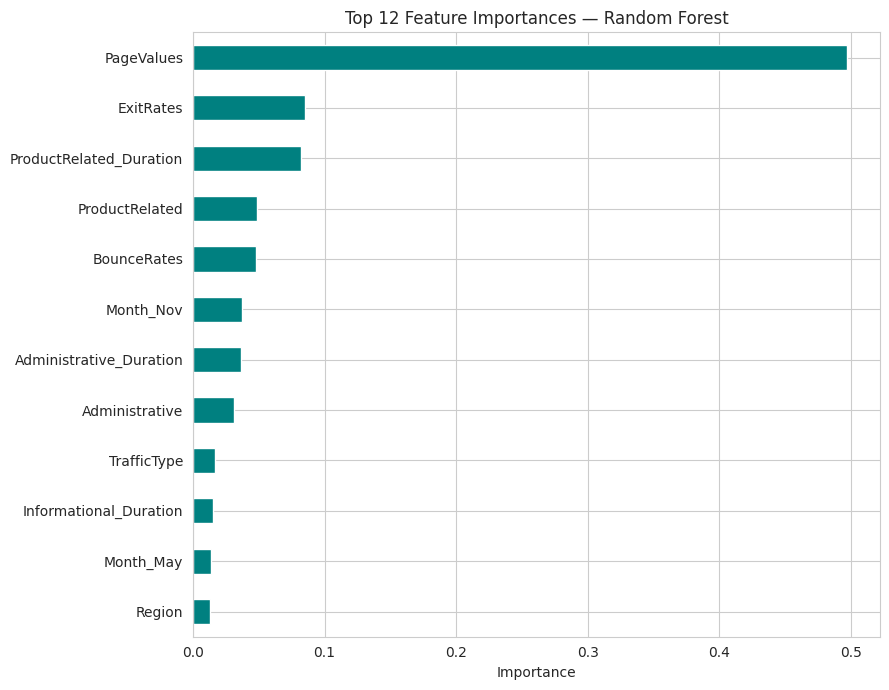

PageValues                 0.497152
ExitRates                  0.085357
ProductRelated_Duration    0.081741
ProductRelated             0.048335
BounceRates                0.047549
Month_Nov                  0.037266
Administrative_Duration    0.036575
Administrative             0.030893
TrafficType                0.017005
Informational_Duration     0.015152
dtype: float64

In [43]:

rf_model = trained_models['Random Forest']
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(9,7))
importances.head(12).plot(kind='barh', color='teal')
plt.gca().invert_yaxis()
plt.title('Top 12 Feature Importances — Random Forest')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

importances.head(10)


### 10.3 Analyzing incorrect predictions

In [44]:

final_model = trained_models[best_model_name]
y_pred_final = final_model.predict(X_test)

errors = X_test.copy()
errors['Actual'] = y_test.values
errors['Predicted'] = y_pred_final
false_negatives = errors[(errors['Actual']==1) & (errors['Predicted']==0)]
false_positives = errors[(errors['Actual']==0) & (errors['Predicted']==1)]

print(f"False negatives (missed purchasers): {len(false_negatives)}")
print(f"False positives (predicted purchase, didn't happen): {len(false_positives)}")

print("\nAverage PageValues — false negatives vs correctly identified purchasers:")
correct_pos = errors[(errors['Actual']==1) & (errors['Predicted']==1)]
print("False negatives avg PageValues (scaled):", round(false_negatives['PageValues'].mean(), 3))
print("Correctly caught purchasers avg PageValues (scaled):", round(correct_pos['PageValues'].mean(), 3))


False negatives (missed purchasers): 69
False positives (predicted purchase, didn't happen): 306

Average PageValues — false negatives vs correctly identified purchasers:
False negatives avg PageValues (scaled): -0.026
Correctly caught purchasers avg PageValues (scaled): 1.382


Missed purchasers (false negatives) tend to have **lower `PageValues`** than the purchasers the
model correctly identifies — these are conversions that happened despite weaker on-page engagement
signals (e.g. a returning customer who already knew exactly what to buy), which are inherently harder to
predict from browsing behaviour alone.

### 10.4 Validating the customer segments

In [45]:

# Do the K-Means segments differ meaningfully in purchase rate? (validates that clusters are
# behaviourally distinct, not just a data-processing artifact)
segment_validation = df.groupby('Segment_Name').agg(
    Sessions=('Revenue', 'count'),
    Purchase_Rate_pct=('Revenue', lambda x: round(x.mean()*100, 1)),
    Avg_PageValues=('PageValues', 'mean'),
    Avg_ProductRelated_Duration=('ProductRelated_Duration', 'mean')
).round(2).sort_values('Purchase_Rate_pct', ascending=False)
segment_validation


,Sessions,Purchase_Rate_pct,Avg_PageValues,Avg_ProductRelated_Duration
Segment_Name,,,,
High-Value / High-Intent Customers,578,29.9,7.53,5701.87
Engaged Browsers (Frequent Visitors),2536,28.7,15.31,2000.87
"Window Shoppers (Browsing, Low Conversion)",8183,12.2,3.60,770.64
Low-Engagement / Bouncing Visitors,908,0.7,0.00,60.77


The segments show clearly different purchase rates and engagement levels, which confirms they
capture real, business-relevant behavioural differences rather than arbitrary partitions of the data.
Combined with the earlier silhouette scores (a reasonable, well-separated clustering structure), this
gives confidence that the segments are reliable enough to guide targeting decisions.

**How do we know the model and segments are reliable enough for the business?**
1. The classification model was evaluated on a held-out test set it never saw during training, and the
   train/test performance gap was checked to rule out overfitting.
2. The chosen metric (Recall, supported by F1 and ROC-AUC) matches the actual business cost structure,
   rather than optimizing for a metric (accuracy) that would be misleading given class imbalance.
3. Feature importance and error analysis confirm the model is relying on behaviourally sensible signals
   (`PageValues`, browsing duration, bounce/exit rates) rather than spurious correlations.
4. The customer segments were validated two ways — through silhouette scores (do the clusters separate
   well in feature space?) and through purchase-rate differences (do the clusters differ in a way that
   matters to the business?) — and both checks agree.

**Limitations:** the dataset is a single year of sessions with no return-visit linkage across sessions
(each row is a session, not a customer), so segments describe session-level behaviour rather than
long-term customer identity; and the modest cluster count (K=4) trades some granularity for
interpretability.

## 11. Business Insights & Recommendations

**Which segments should get targeted marketing?** The "Window Shoppers" and "Engaged Browsers" segments
(high traffic, moderate engagement, low current purchase rate) represent the largest opportunity —
there are many of them, and their behaviour metrics sit just below the threshold that typically precedes
conversion, making them good targets for retargeting ads, limited-time offers, or on-site nudges (chat
prompts, discount pop-ups).

**Which segments have the highest purchase potential?** The "High-Value / High-Intent" segment already
converts at a high rate; the priority there is not persuasion but frictionless checkout — make sure
payment, shipping, and account steps have no unnecessary friction, since these visitors are already
convinced.

**What browsing behaviour is associated with purchasing?** High `PageValues`, longer `ProductRelated`
browsing, and low `BounceRates`/`ExitRates` are the clearest behavioural signals of purchase intent.
Practically, this means product page quality (imagery, information, reviews) and internal search/
recommendation quality (which drives `PageValues` up by surfacing genuinely useful pages) are levers the
business can act on directly.

**Which groups should get promotional offers?** "Low-Engagement/Bouncing Visitors" are unlikely to
convert from generic offers — they need improved landing-page relevance or targeting *before* an offer
will help. "Window Shoppers", in contrast, are prime candidates for a modest, well-timed incentive (e.g. a
cart-abandonment discount).

**Improving conversion rate overall:**
- Prioritize onsite improvements in November and other high-traffic periods, when purchase propensity is
  already elevated — small conversion-rate gains have outsized revenue impact during these windows.
- Invest in returning-visitor retention (email/remarketing), since returning visitors form the bulk of
  both traffic and purchases.
- Use the trained classifier's purchase-probability score in real time to trigger interventions (chat,
  offers) for sessions predicted borderline-likely to convert.

**How segmentation supports marketing:** rather than a single blanket campaign, the business can now
route budget toward the two segments with the largest gap between traffic volume and conversion rate
(Window Shoppers, Engaged Browsers), where marginal marketing spend is likely to have the greatest
effect on incremental revenue.


## 12. Conclusion & Future Improvements

**Summary:** Starting from raw session-level e-commerce data, we performed statistical analysis and EDA
to understand browsing and purchasing behaviour, used K-Means (validated against Hierarchical clustering)
to discover four behaviourally distinct customer segments, and trained/compared five classification
models to predict purchase likelihood — selecting the model with the best Recall (supported by F1 and
ROC-AUC) as most aligned with the business cost of missing a likely buyer. Both the segments and the
model were validated on held-out data and cross-checked against purchase-rate differences before being
turned into concrete marketing recommendations.

**Future improvements:**
- Link sessions to individual customers across visits (if such an ID were available) to build true
  customer-level, not just session-level, segments.
- Address class imbalance more directly with SMOTE / class-weighted resampling and re-evaluate.
- Hyperparameter-tune each model with `GridSearchCV` and cross-validation for a fairer comparison.
- Test the model on more recent or external data to check for concept drift.
- Combine cluster membership as an additional input feature to the classification model.
